## Soal 1 — Membuat sistem basis data perpustakaan
### Membuat database dan tiga tabel

Saya menggunakan tiga tabel, yaitu **buku**, **anggota**, dan **peminjaman**. Kolom `id_anggota` serta `id_buku` pada tabel peminjaman merupakan **foreign key**. Saya mengaktifkan pemeriksaan foreign key dengan `PRAGMA foreign_keys = ON` agar relasi datanya tetap benar.

In [ ]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

conn = sqlite3.connect("perpustakaan.db")
conn.execute("PRAGMA foreign_keys = ON;")

conn.executescript("""
DROP TABLE IF EXISTS peminjaman;
DROP TABLE IF EXISTS anggota;
DROP TABLE IF EXISTS buku;

CREATE TABLE buku (
    id INTEGER PRIMARY KEY,
    judul TEXT NOT NULL,
    penulis TEXT NOT NULL,
    tahun INTEGER NOT NULL
);

CREATE TABLE anggota (
    id INTEGER PRIMARY KEY,
    nama TEXT NOT NULL,
    email TEXT NOT NULL UNIQUE
);

CREATE TABLE peminjaman (
    id INTEGER PRIMARY KEY,
    id_anggota INTEGER NOT NULL,
    id_buku INTEGER NOT NULL,
    tgl_pinjam TEXT NOT NULL,
    tgl_kembali TEXT,
    FOREIGN KEY (id_anggota) REFERENCES anggota(id),
    FOREIGN KEY (id_buku) REFERENCES buku(id),
    CHECK (tgl_kembali IS NULL OR tgl_kembali >= tgl_pinjam)
);
""")
conn.commit()


tabel = pd.read_sql_query("""
SELECT name AS nama_tabel
FROM sqlite_master
WHERE type = 'table' AND name IN ('buku', 'anggota', 'peminjaman')
ORDER BY name;
""", conn)
print("Tabel berhasil dibuat:")
print(tabel.to_string(index=False))

Tabel berhasil dibuat:
nama_tabel
   anggota
      buku
peminjaman


### 1a. Menambahkan 5 buku dan 3 anggota

Saya memasukkan **5 buku** serta **3 anggota** menggunakan `executemany()` dengan placeholder `?`. Dengan cara ini, nilai data dipisahkan dari perintah SQL dan lebih aman daripada menyusun query menggunakan gabungan string.

In [ ]:
data_buku = [
    (1, "Laskar Pelangi", "Andrea Hirata", 2005),
    (2, "Bumi Manusia", "Pramoedya Ananta Toer", 1980),
    (3, "Filosofi Teras", "Henry Manampiring", 2018),
    (4, "Negeri 5 Menara", "Ahmad Fuadi", 2009),
    (5, "Atomic Habits", "James Clear", 2018)
]

data_anggota = [
    (1, "Alya Putri", "alya@example.com"),
    (2, "Bima Pratama", "bima@example.com"),
    (3, "Citra Lestari", "citra@example.com")
]

conn.executemany(
    "INSERT INTO buku (id, judul, penulis, tahun) VALUES (?, ?, ?, ?)",
    data_buku
)
conn.executemany(
    "INSERT INTO anggota (id, nama, email) VALUES (?, ?, ?)",
    data_anggota
)
conn.commit()

print("DATA BUKU (5 BARIS)")
print(pd.read_sql_query("SELECT * FROM buku ORDER BY id", conn).to_string(index=False))
print("\nDATA ANGGOTA (3 BARIS)")
print(pd.read_sql_query("SELECT * FROM anggota ORDER BY id", conn).to_string(index=False))

DATA BUKU (5 BARIS)
 id           judul               penulis  tahun
  1  Laskar Pelangi         Andrea Hirata   2005
  2    Bumi Manusia Pramoedya Ananta Toer   1980
  3  Filosofi Teras     Henry Manampiring   2018
  4 Negeri 5 Menara           Ahmad Fuadi   2009
  5   Atomic Habits           James Clear   2018

DATA ANGGOTA (3 BARIS)
 id          nama             email
  1    Alya Putri  alya@example.com
  2  Bima Pratama  bima@example.com
  3 Citra Lestari citra@example.com


### 1b. Menambahkan 4 transaksi peminjaman

Saya membuat **4 transaksi**. Tiga di antaranya sudah memiliki tanggal kembali, sementara transaksi nomor **3** belum dikembalikan sehingga `tgl_kembali` berisi `NULL` (`None` pada Python).

In [ ]:
data_peminjaman = [
    (1, 1, 1, "2026-11-02", "2026-11-09"),
    (2, 2, 2, "2026-11-04", "2026-11-13"),
    (3, 1, 3, "2026-11-10", None),
    (4, 3, 4, "2026-11-11", "2026-11-19")
]

conn.executemany("""
INSERT INTO peminjaman (id, id_anggota, id_buku, tgl_pinjam, tgl_kembali)
VALUES (?, ?, ?, ?, ?)
""", data_peminjaman)
conn.commit()

print("DATA PEMINJAMAN (4 TRANSAKSI)")
print(pd.read_sql_query("SELECT * FROM peminjaman ORDER BY id", conn).to_string(index=False))

jumlah_belum_kembali = pd.read_sql_query(
    "SELECT COUNT(*) AS total FROM peminjaman WHERE tgl_kembali IS NULL", conn
).loc[0, "total"]
print(f"\nJumlah peminjaman yang belum dikembalikan: {jumlah_belum_kembali}")

DATA PEMINJAMAN (4 TRANSAKSI)
 id  id_anggota  id_buku tgl_pinjam tgl_kembali
  1           1        1 2026-11-02  2026-11-09
  2           2        2 2026-11-04  2026-11-13
  3           1        3 2026-11-10        None
  4           3        4 2026-11-11  2026-11-19

Jumlah peminjaman yang belum dikembalikan: 1


### 1c. Menampilkan daftar peminjaman lengkap menggunakan JOIN

Saya menggunakan `INNER JOIN` untuk menghubungkan tabel peminjaman dengan tabel anggota dan buku. Hasilnya menampilkan **nama anggota, judul buku, tanggal pinjam, dan tanggal kembali**, jadi kita tidak hanya melihat angka ID.

In [ ]:
query_join = """
SELECT
    p.id AS id_peminjaman,
    a.nama AS nama_anggota,
    b.judul AS judul_buku,
    p.tgl_pinjam,
    p.tgl_kembali
FROM peminjaman AS p
INNER JOIN anggota AS a ON p.id_anggota = a.id
INNER JOIN buku AS b ON p.id_buku = b.id
ORDER BY p.id;
"""

df_peminjaman = pd.read_sql_query(query_join, conn)
print("HASIL JOIN DAFTAR PEMINJAMAN")
print(df_peminjaman.to_string(index=False))

HASIL JOIN DAFTAR PEMINJAMAN
 id_peminjaman  nama_anggota      judul_buku tgl_pinjam tgl_kembali
             1    Alya Putri  Laskar Pelangi 2026-11-02  2026-11-09
             2  Bima Pratama    Bumi Manusia 2026-11-04  2026-11-13
             3    Alya Putri  Filosofi Teras 2026-11-10        None
             4 Citra Lestari Negeri 5 Menara 2026-11-11  2026-11-19


### 1d. Menghitung total buku yang dipinjam tiap anggota

Saya memakai `GROUP BY` berdasarkan anggota dan fungsi agregasi `COUNT(p.id)` untuk menghitung jumlah **transaksi peminjaman**. Saya memilih `LEFT JOIN` agar anggota yang belum meminjam buku juga tetap bisa ditampilkan dengan jumlah 0.

In [ ]:
query_agregasi = """
SELECT
    a.id AS id_anggota,
    a.nama AS nama_anggota,
    COUNT(p.id) AS total_buku_dipinjam
FROM anggota AS a
LEFT JOIN peminjaman AS p ON p.id_anggota = a.id
GROUP BY a.id, a.nama
ORDER BY total_buku_dipinjam DESC, a.id;
"""

df_total = pd.read_sql_query(query_agregasi, conn)
print("TOTAL PEMINJAMAN PER ANGGOTA")
print(df_total.to_string(index=False))

print(f"\nTotal seluruh transaksi peminjaman: {df_total['total_buku_dipinjam'].sum()}")

TOTAL PEMINJAMAN PER ANGGOTA
 id_anggota  nama_anggota  total_buku_dipinjam
          1    Alya Putri                    2
          2  Bima Pratama                    1
          3 Citra Lestari                    1

Total seluruh transaksi peminjaman: 4


## Soal 2 — Analisis data peminjaman dengan Pandas
### 2a. Membuat DataFrame dari query SQL

Pada bagian ini saya menggunakan `pd.read_sql_query()` untuk mengambil hasil **JOIN** dari SQLite dan mengubahnya menjadi DataFrame Pandas. Hasilnya bisa digunakan untuk pengolahan serta visualisasi data.

In [ ]:
df_analisis = pd.read_sql_query(query_join, conn)

print("DATAFRAME HASIL QUERY SQL")
print(df_analisis.to_string(index=False))
print(f"\nJumlah baris: {len(df_analisis)}")
print("Nama kolom:", df_analisis.columns.tolist())

DATAFRAME HASIL QUERY SQL
 id_peminjaman  nama_anggota      judul_buku tgl_pinjam tgl_kembali
             1    Alya Putri  Laskar Pelangi 2026-11-02  2026-11-09
             2  Bima Pratama    Bumi Manusia 2026-11-04  2026-11-13
             3    Alya Putri  Filosofi Teras 2026-11-10        None
             4 Citra Lestari Negeri 5 Menara 2026-11-11  2026-11-19

Jumlah baris: 4
Nama kolom: ['id_peminjaman', 'nama_anggota', 'judul_buku', 'tgl_pinjam', 'tgl_kembali']


### 2b. Eksplorasi: menghitung durasi dan melihat pola peminjaman

Saya mengubah kolom tanggal menjadi tipe `datetime`, lalu menghitung selisih antara tanggal kembali dan tanggal pinjam dalam satuan hari. Untuk transaksi yang masih aktif, durasi selesai **tidak dihitung** karena bukunya memang belum dikembalikan.

Sebagai informasi tambahan, saya menghitung berapa hari buku tersebut sudah dipinjam sampai **tanggal referensi 25 November 2026**. Tanggal ini hanya digunakan sebagai batas pengamatan supaya hasil notebook tetap sama jika dijalankan pada hari lain.

In [ ]:
df_durasi = df_analisis.copy()

df_durasi["tgl_pinjam"] = pd.to_datetime(df_durasi["tgl_pinjam"])
df_durasi["tgl_kembali"] = pd.to_datetime(df_durasi["tgl_kembali"])

df_durasi["durasi_selesai_hari"] = (
    df_durasi["tgl_kembali"] - df_durasi["tgl_pinjam"]
).dt.days.astype("Int64")

df_durasi["status"] = df_durasi["tgl_kembali"].apply(
    lambda tgl: "Belum kembali" if pd.isna(tgl) else "Sudah kembali"
)

tanggal_referensi = pd.Timestamp("2026-11-25")
masih_dipinjam = df_durasi["tgl_kembali"].isna()
df_durasi["lama_aktif_hari"] = pd.Series(pd.NA, index=df_durasi.index, dtype="Int64")
df_durasi.loc[masih_dipinjam, "lama_aktif_hari"] = (
    tanggal_referensi - df_durasi.loc[masih_dipinjam, "tgl_pinjam"]
).dt.days.to_numpy()

kolom_tampil = [
    "nama_anggota", "judul_buku", "tgl_pinjam", "tgl_kembali",
    "status", "durasi_selesai_hari", "lama_aktif_hari"
]
print("HASIL PERHITUNGAN DURASI")
print(df_durasi[kolom_tampil].to_string(index=False))

selesai = df_durasi["durasi_selesai_hari"].dropna()
print("\nRINGKASAN POLA PEMINJAMAN")
print(f"Jumlah transaksi: {len(df_durasi)}")
print(f"Sudah kembali: {(~masih_dipinjam).sum()}")
print(f"Belum kembali: {masih_dipinjam.sum()}")
print(f"Rata-rata durasi untuk yang sudah kembali: {selesai.mean():.2f} hari")
print(f"Durasi terpendek (yang sudah kembali): {selesai.min()} hari")
print(f"Durasi terpanjang (yang sudah kembali): {selesai.max()} hari")
print(f"Anggota dengan peminjaman terbanyak: {df_total.iloc[0]['nama_anggota']}")

HASIL PERHITUNGAN DURASI
 nama_anggota      judul_buku tgl_pinjam tgl_kembali        status  durasi_selesai_hari  lama_aktif_hari
   Alya Putri  Laskar Pelangi 2026-11-02  2026-11-09 Sudah kembali                    7             <NA>
 Bima Pratama    Bumi Manusia 2026-11-04  2026-11-13 Sudah kembali                    9             <NA>
   Alya Putri  Filosofi Teras 2026-11-10         NaT Belum kembali                 <NA>               15
Citra Lestari Negeri 5 Menara 2026-11-11  2026-11-19 Sudah kembali                    8             <NA>

RINGKASAN POLA PEMINJAMAN
Jumlah transaksi: 4
Sudah kembali: 3
Belum kembali: 1
Rata-rata durasi untuk yang sudah kembali: 8.00 hari
Durasi terpendek (yang sudah kembali): 7 hari
Durasi terpanjang (yang sudah kembali): 9 hari
Anggota dengan peminjaman terbanyak: Alya Putri


### 2c. Visualisasi distribusi data dengan Matplotlib

Saya membuat **diagram batang jumlah buku yang dipinjam per anggota**. Sumbu X menunjukkan nama anggota dan sumbu Y menunjukkan jumlah peminjaman. Grafik ini memudahkan saya melihat anggota yang paling sering meminjam buku.

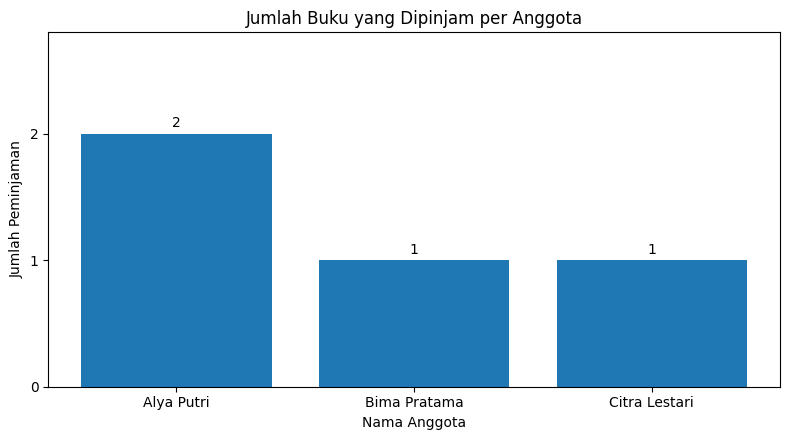

In [ ]:
plt.figure(figsize=(8, 4.5))
plt.bar(df_total["nama_anggota"], df_total["total_buku_dipinjam"])
plt.title("Jumlah Buku yang Dipinjam per Anggota")
plt.xlabel("Nama Anggota")
plt.ylabel("Jumlah Peminjaman")
plt.yticks(range(0, int(df_total["total_buku_dipinjam"].max()) + 2))

for i, total in enumerate(df_total["total_buku_dipinjam"]):
    plt.text(i, total + 0.05, str(total), ha="center")

plt.ylim(0, df_total["total_buku_dipinjam"].max() + 0.8)
plt.tight_layout()
plt.show()

**Visualisasi tambahan:** Saya juga membuat histogram untuk membandingkan durasi **tiga peminjaman yang sudah selesai**. Transaksi yang masih aktif tidak dimasukkan karena belum memiliki durasi peminjaman final.

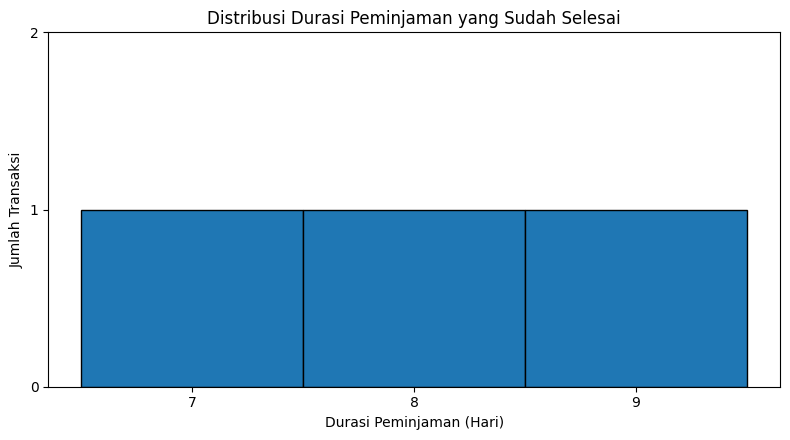

In [ ]:
durasi_selesai = df_durasi["durasi_selesai_hari"].dropna().astype(int)

plt.figure(figsize=(8, 4.5))
plt.hist(durasi_selesai, bins=[6.5, 7.5, 8.5, 9.5], edgecolor="black")
plt.title("Distribusi Durasi Peminjaman yang Sudah Selesai")
plt.xlabel("Durasi Peminjaman (Hari)")
plt.ylabel("Jumlah Transaksi")
plt.xticks([7, 8, 9])
plt.yticks([0, 1, 2])
plt.tight_layout()
plt.show()

## Pemeriksaan otomatis hasil pengerjaan

Saya menambahkan pengujian sederhana agar jumlah data, relasi tabel, hasil agregasi, dan perhitungan durasi bisa diperiksa secara otomatis. Jika semua benar, sel ini akan menampilkan **LULUS** tanpa error.

In [ ]:
assert pd.read_sql_query("SELECT COUNT(*) AS n FROM buku", conn).loc[0, "n"] == 5
assert pd.read_sql_query("SELECT COUNT(*) AS n FROM anggota", conn).loc[0, "n"] == 3
assert pd.read_sql_query("SELECT COUNT(*) AS n FROM peminjaman", conn).loc[0, "n"] == 4
assert jumlah_belum_kembali >= 1
assert len(df_peminjaman) == 4
assert df_total["total_buku_dipinjam"].sum() == 4


assert conn.execute("PRAGMA foreign_key_check;").fetchall() == []

assert sorted(durasi_selesai.tolist()) == [7, 8, 9]
assert abs(durasi_selesai.mean() - 8.0) < 0.00001
assert df_durasi["lama_aktif_hari"].dropna().tolist() == [15]
assert df_total.loc[0, "nama_anggota"] == "Alya Putri"

print("LULUS: semua persyaratan Soal 1 dan 2 berhasil diperiksa tanpa error.")


conn.close()
print("Koneksi database sudah ditutup.")

LULUS: semua persyaratan Soal 1 dan 2 berhasil diperiksa tanpa error.


Koneksi database sudah ditutup.
